In [1]:
# Import Libs
import xarray as xr
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [9]:
num = "002"

tidal_data = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/mom_input/2t.tides-three-boundary-rect/tu_segment_{}.nc".format(num))
tidal_data_elv = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/mom_input/2t.tides-three-boundary-rect/tz_segment_{}.nc".format(num))
hgrid = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/mom_input/2t.tides-three-boundary-rect/hgrid.nc")
tidal_data

<xarray.Dataset>
Dimensions:             (nx_segment_002: 1513, time: 1, constituent: 1, ny_segment_002: 1)
Coordinates:
    lon_segment_002     (nx_segment_002) float64 ...
    lat_segment_002     (nx_segment_002) float64 ...
  * time                (time) datetime64[ns] 2005-01-01
Dimensions without coordinates: nx_segment_002, constituent, ny_segment_002
Data variables:
    uamp_segment_002    (time, constituent, ny_segment_002, nx_segment_002) float32 ...
    vamp_segment_002    (time, constituent, ny_segment_002, nx_segment_002) float32 ...
    uphase_segment_002  (time, constituent, ny_segment_002, nx_segment_002) float32 ...
    vphase_segment_002  (time, constituent, ny_segment_002, nx_segment_002) float32 ...

Text(0.5, 1.0, 'NWA12 mesh (every 10 points)')

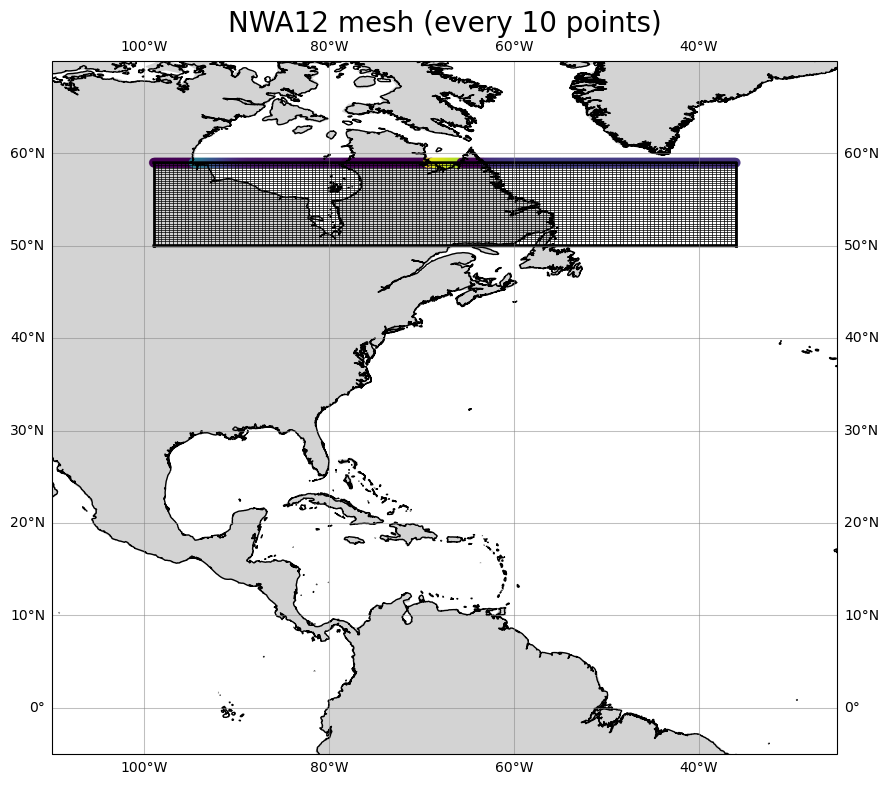

In [10]:
# Plot and save the NWA12 Mesh grid

plt.figure(figsize=(12,9))

# the central_longitude parameter tells the projection where to be centered for this axes
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-110, -25, -5, 70], ccrs.PlateCarree())
gl = ax.gridlines(linewidth=0.75, color='gray', alpha=0.5, linestyle='-', draw_labels=True)

# add geographic information
ax.add_feature(cartopy.feature.LAND, fc='lightgray')
#ax.add_feature(cartopy.feature.OCEAN)
ax.coastlines(resolution='10m')  # looks better with resolution='10m'
#ax.add_feature(cartopy.feature.BORDERS, linestyle='-', lw=.1)
#ax.add_feature(cartopy.feature.RIVERS)

k=10
ax.plot(hgrid.x[::k,::k], hgrid.y[::k,::k], color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())
ax.plot(hgrid.x[::k,::k].T, hgrid.y[::k,::k].T, color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())

ax.plot(hgrid.x[0,:], hgrid.y[0,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[-1,:], hgrid.y[-1,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,0], hgrid.y[:,0], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,-1], hgrid.y[:,-1], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
scatter = ax.scatter(tidal_data.lon_segment_002.values, tidal_data.lat_segment_002.values, c= tidal_data_elv.zamp_segment_002[0][0], cmap='viridis', transform=ccrs.PlateCarree(), alpha=0.6)

plt.title('NWA12 mesh (every {} points)'.format(k), fontsize=20)



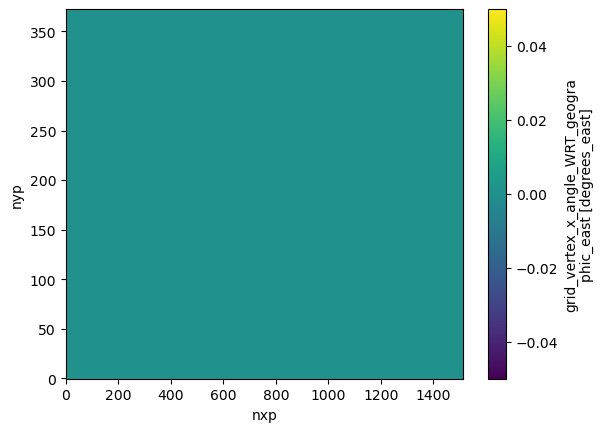

In [4]:
hgrid["angle_dx"].plot()


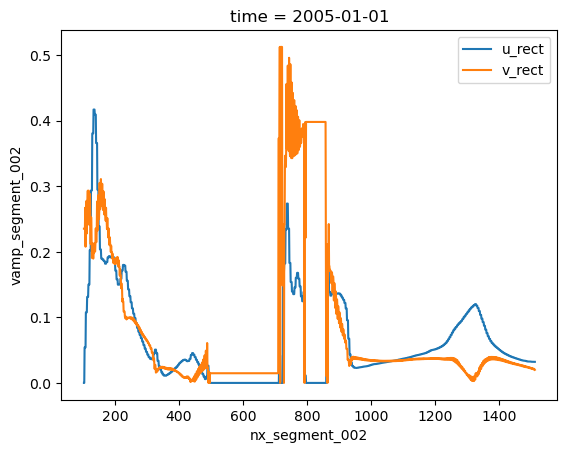

In [5]:

tidal_data["uamp_segment_{}".format(num)].plot(label="u_rect")
tidal_data["vamp_segment_{}".format(num)].plot(label="v_rect")

plt.legend()

In [6]:
tidal_data["lat_segment_{}".format(num)].values

array([59., 59., 59., ..., 59., 59., 59.])

In [7]:
tidal_data["lon_segment_{}".format(num)].values

array([261.        , 261.04166667, 261.08333333, ..., 323.91666667,
       323.95833333, 324.        ])

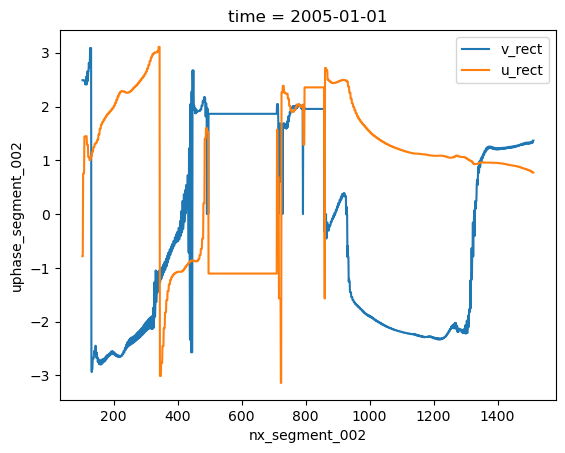

In [8]:

tidal_data["vphase_segment_{}".format(num)].plot(label="v_rect")
tidal_data["uphase_segment_{}".format(num)].plot(label="u_rect")

plt.legend()

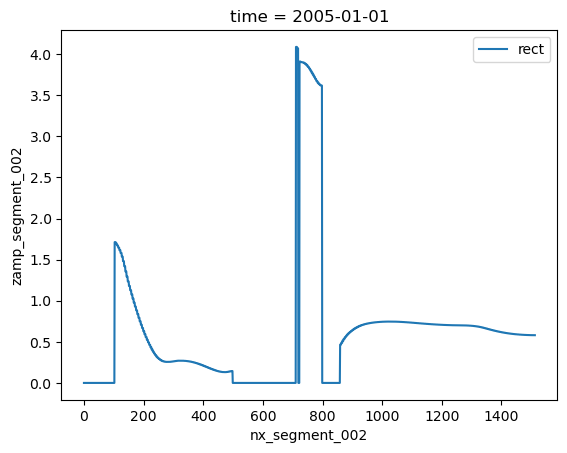

In [9]:
tidal_data_elv["zamp_segment_{}".format(num)].plot(label = "rect")
plt.legend()

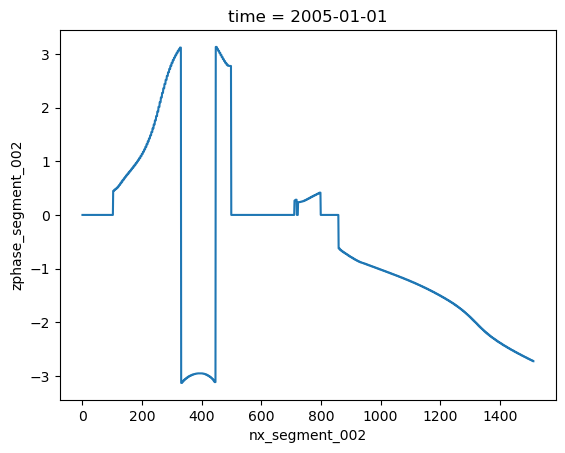

In [10]:
tidal_data_elv["zphase_segment_{}".format(num)].plot()
